In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import sys
sys.path.append('../../../python_modules/')
# plt.rcdefaults() 
plt.rcParams['figure.dpi'] = 200
plt.rcParams['pdf.fonttype'] = '42'

from domino.models.domino_models import DominoSingleOutput
from domino.utils import tools
from domino.data.domino_data import GenomeDataset
# import pytorch_lightning as pl
from domino.data.data import preprocess_data, process_bed_file_df
from domino.utils.tools import seq_from_df
import matplotlib.ticker as mticker
from generic_plotting_functions import *

import scipy.stats as stats
import pandas as pd
import os
import numpy as np
import pysam
import fanc
import fanc.plotting as fancplot

from domino.utils.plotting import plot_attribution

import coolbox
from coolbox.api import *

In [2]:
model_dir = '/scratch/gpfs/PRITYKIN/brendan/domino/output/06_12_2026_final_nc14_no_mig/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu/'

TRAIN_df = pd.read_csv(os.path.join(model_dir, 'TRAIN_df.csv'))
VAL_df = pd.read_csv(os.path.join(model_dir, 'VAL_df.csv'))
TEST_df = pd.read_csv(os.path.join(model_dir, 'TEST_df.csv'))

In [3]:
# load model
model_checkpoint_path = f"{model_dir}/checkpoint/{os.listdir(model_dir + '/checkpoint')[0]}"
model = DominoSingleOutput.load_from_checkpoint(model_checkpoint_path, activation='gelu')
model.eval()

row = TEST_df.query('start == 13485401').iloc[0]

chrom, start, end = row.chrom, row.start, row.end

resolution=200
num_merged=11
delta=2
ws=1
 
data_dir = '/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing'
data = fanc.load(f'{data_dir}/mcools/new_nc14_embryo_merged_all_{num_merged}.mcool@{resolution}')

fc dim 206
extra dim 6


In [4]:
def get_true_track(boundary, ins_score_context_bin_width=10, resolution=200, bp_radius=20_000):
    ins_ws=1
    ins_dir = "/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/insulations/insulation_files"
    ins1_path = f"{ins_dir}/new_nc14_embryo_merged_all_11.resolution=200bp.insulation_{ins_ws}kb.bed"
    ins_score1 = process_bed_file_df(ins1_path, target_col='ins_score')
    
    # get insulation around boundary of interest
    chrom, start, end = boundary
    tmp = ins_score1.query('chrom == @chrom and start == @start and end==@end')
    bin_radius = bp_radius // resolution
    locus_df = ins_score1.iloc[tmp.index.item() - bin_radius:tmp.index.item() + bin_radius + 1]
    
    ins_score_context_bin_width=10
    idxs_pos = np.array([np.arange(i-ins_score_context_bin_width, i+ins_score_context_bin_width+1) for i in locus_df.index])
    y_pos = np.array([np.array(ins_score1['ins_score'][idx_arr]) for idx_arr in idxs_pos]) # context with middle bin
    
    demeaned_y1_pos = y_pos - np.mean(y_pos, axis=1)[:, np.newaxis]
    middle_points1_pos = demeaned_y1_pos[:, ins_score_context_bin_width]

    
    x, y = np.arange(len(middle_points1_pos)), middle_points1_pos
    return x, y

import pysam
from domino.utils.tools import seq_from_df
def get_predicted_track(boundary, ins_score_context_bin_width=10, resolution=200, bp_radius=20_000):
    ins_ws=1
    ins_dir = "/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/insulations/insulation_files"
    ins1_path = f"{ins_dir}/new_nc14_embryo_merged_all_11.resolution=200bp.insulation_{ins_ws}kb.bed"
    ins_score1 = process_bed_file_df(ins1_path, target_col='ins_score')

    # get insulation around boundary of interest
    chrom, start, end = boundary
    tmp = ins_score1.query('chrom == @chrom and start == @start and end==@end')
    bin_radius = bp_radius // resolution
    locus_df = ins_score1.iloc[tmp.index.item() - bin_radius:tmp.index.item() + bin_radius + 1]
    
    genome_path = '/scratch/gpfs/PRITYKIN/brendan/deeplearning-microc/data/dm6.fa'
    genome_fasta = pysam.FastaFile(genome_path)

    locus_df['direction'] = ["+"] * len(locus_df)
    locus_df.reset_index(inplace=True, drop=True)
    seqs = seq_from_df(genome_fasta, locus_df, DNA_context_length=16*200)
    
    predictions = model(seqs.to('cuda'))
    predictions = predictions.cpu().detach().flatten()
    
    x, y = np.arange(len(predictions)), predictions
    return x, y
    
def save_track(y, boundary, fn, resolution=200, offset=20_000):
    chrom, start, end = boundary
    df = pd.DataFrame({
        'chrom': [chrom] * len(y),
        'start': np.arange(start - offset, end + offset, resolution),
        'end': np.arange(start - offset, end + offset, resolution) + resolution,
        'value': y
    })
    # Save to BEDGraph
    df.to_csv(fn, sep='\t', header=False, index=False)
    return df

In [5]:
# boundary = (chrom, start, end)

# _, obs_y = get_true_track(boundary)
# _, pred_y = get_predicted_track(boundary)

# obs_df = save_track(obs_y, boundary, 'final_observed.bedGraph')
# pred_df = save_track(pred_y, boundary, 'final_predicted.bedGraph')

# df = pd.DataFrame({
#     "chrom": ["chr2R"]*len(obs_y),
#     "start": np.arange(start-20_000, end+20_000, 200),
#     "end": np.arange(start-20_000, end+20_000, 200) + 200,
#     "score": y
# })

# df.to_csv('final_observed.bedGraph',  sep='\t', header=False, index=False)

In [6]:
all_nc14_boundaries = pd.read_csv('/scratch/gpfs/PRITYKIN/brendan/domino/output/06_12_2026_final_nc14_no_mig/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu/final_nc14_boundaries_df.bound_score_gt_1.csv').drop_duplicates(['chrom', 'start', 'end'])[['chrom', 'start', 'end']]

midpoints = (all_nc14_boundaries['start'] + all_nc14_boundaries['start']) // 2
all_nc14_boundaries['start'] = midpoints
all_nc14_boundaries['end'] = midpoints
all_nc14_boundaries['dot'] = ['.'] * len(all_nc14_boundaries)
all_nc14_boundaries['ins'] = [0] * len(all_nc14_boundaries)
all_nc14_boundaries['sign'] = ['+'] * len(all_nc14_boundaries)

# all_nc14_boundaries.to_csv('all_nc14_boundaries.bed', sep='\t', index=False, header=False)

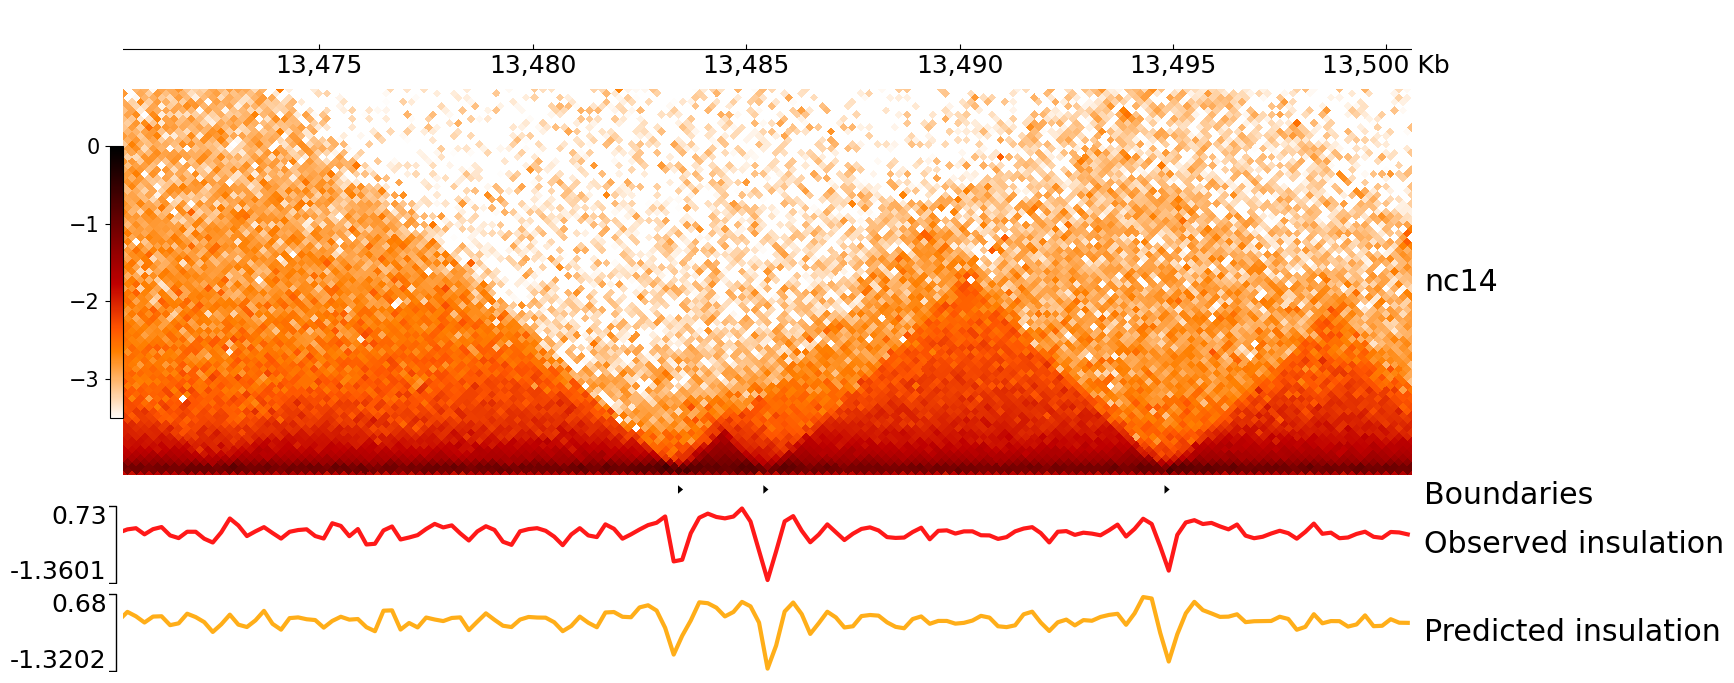

In [7]:
plt.rcParams.update(plt.rcParamsDefault)
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['font.size'] = 18

MCOOL_DATA_DIR='/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/mcools/'
BOUND_DATA_DIR='/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/boundaries/'
RESOLUTION=200
NUM_MERGED=11

HIC_KWARGS = dict(
    style='window', 
    resolution=200, 
    depth_ratio=0.6, 
    cmap='gist_heat_r', 
    norm='no', 
    transform='log10', 
    max_value=0, 
    min_value=-3.5, 
    grid=False,
)

BEDGRAPH_KWARGS = dict(
    border_only=True,
    labels=False,
    num_rows=1,
    linewidth=4,
    height=2,
    style='line',
    line_width=3,
    alpha=0.9,
    border_color=None,
    properties=dict(fontsize=16),
)

BED_KWARGS = dict(
    border_only=False,
    labels=False,
    num_rows=1,
    linewidth=0,
    height=0.5,
    properties=dict(line_width=5, fontsize=16),
    border_color=None,
    marker='s',
    
)

frame = [
    coolbox.api.XAxis(fontsize=18, show_chrom=True),

    # Map
    coolbox.api.HiCMat(f"{MCOOL_DATA_DIR}/new_nc14_embryo_merged_all_11.mcool", title='nc14', **HIC_KWARGS),
    coolbox.api.Spacer(), coolbox.api.TrackHeight(0.25),

    # Boundaries
    # coolbox.api.BED(f"{BOUND_DATA_DIR}/midpoint.bed", color='k', title='Boundaries', **BED_KWARGS),
    coolbox.api.BED("all_nc14_boundaries.bed", color='k', title='Boundaries', **BED_KWARGS),
    # coolbox.api.BED(f"{BOUND_DATA_DIR}/nc14_embryo_merged_all_11.resolution=200bp.delta=2.window_size=1kb.boundaries.bed", color='black', title='Boundares', **BED_KWARGS),
    # coolbox.api.Spacer(), coolbox.api.TrackHeight(0.25),
    
    # Insulation tracks
    coolbox.api.BedGraph('final_observed.bedGraph', title='Observed insulation', color="red",  **BEDGRAPH_KWARGS),
    coolbox.api.Spacer(), coolbox.api.TrackHeight(0.25),
    coolbox.api.BedGraph('final_predicted.bedGraph', title='Predicted insulation', color="orange",  **BEDGRAPH_KWARGS)
]
from functools import reduce

frame = reduce(lambda x, y: x + y, frame)
fig = frame.plot(f"{chrom}:{start -15_000}-{end  + 15_000}")
fig.set(facecolor="white")
fig.savefig("/scratch/gpfs/PRITYKIN/brendan/domino/figures/test_pred_locus.pdf", format="pdf", dpi=300, bbox_inches='tight')
display(fig)

In [8]:
def read_bedgraph(fn):
    df = pd.read_csv(
        fn, 
        sep="\t", 
        comment="t",  # Ignores lines starting with 'track'
        names=["chrom", "start", "end", "ins"]
    )
    return df

In [9]:
obs_y = read_bedgraph('final_observed.bedGraph').ins.tolist()
pred_y = read_bedgraph('final_predicted.bedGraph').ins.tolist()

stats.pearsonr(obs_y, pred_y)[0]
stats.spearmanr(obs_y, pred_y)[0]

0.8353184572188562

# Predictive power

Only values in test set where both are finite are considered for correlation.

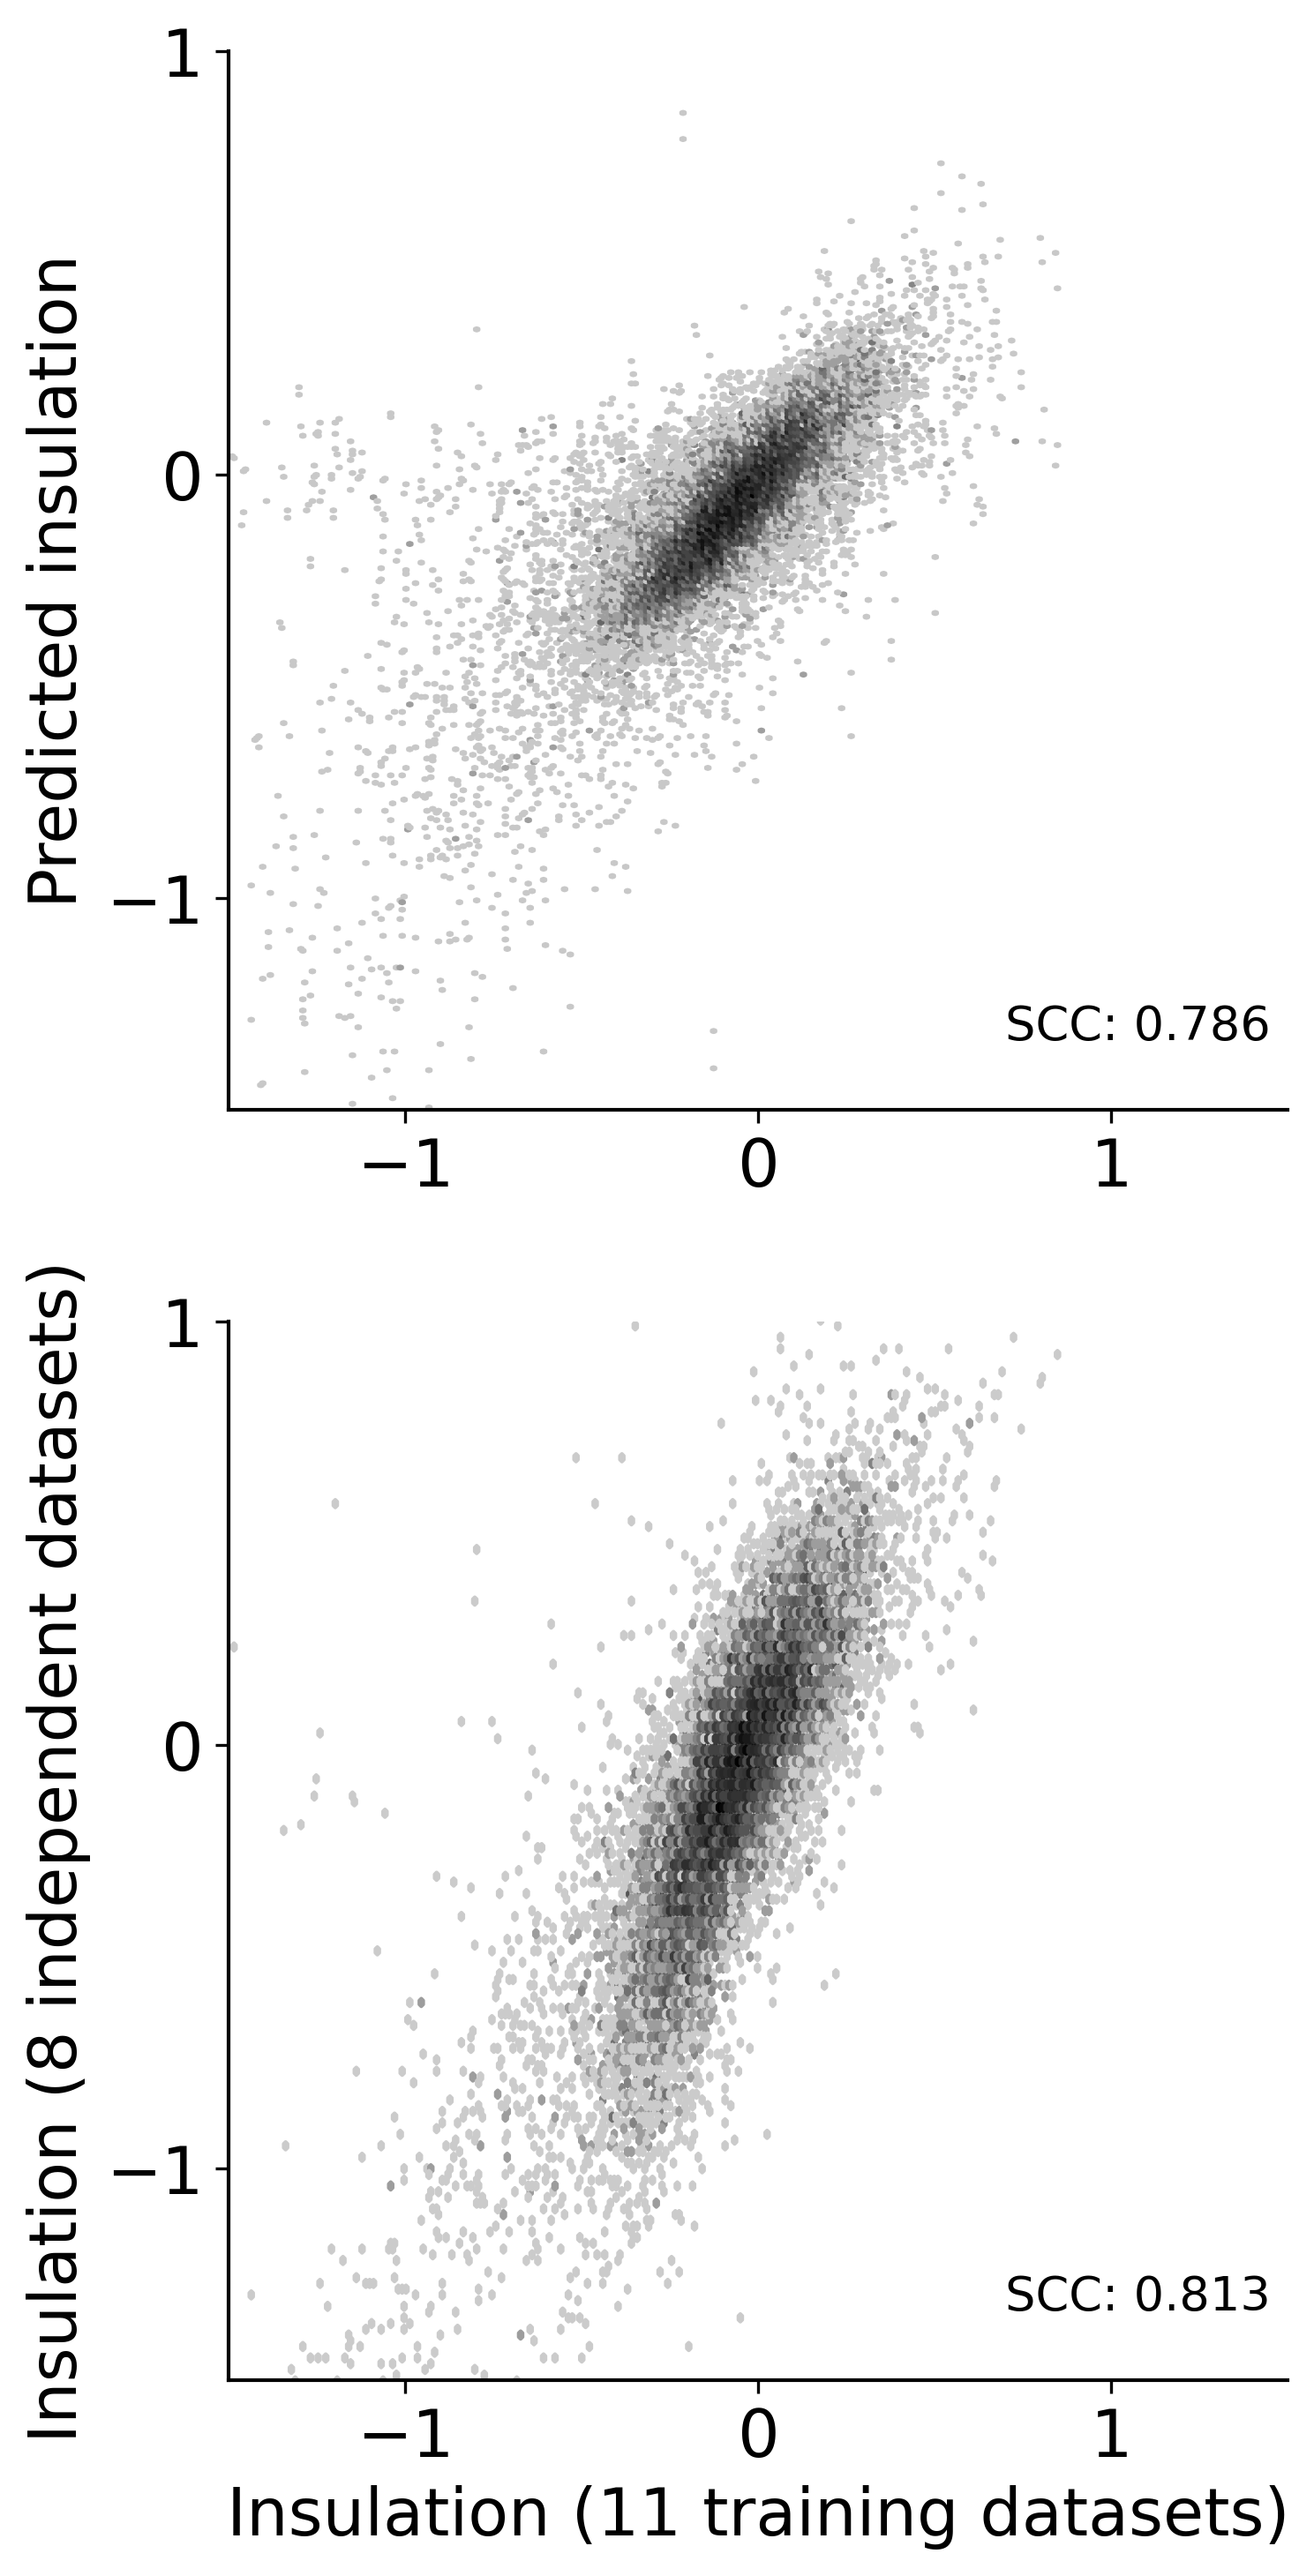

In [11]:
fig, axs = init_subplots_exact(2,2,dpi=300)

plt.sca(axs[0])
ax=axs[0]
X = TEST_df[np.isfinite(TEST_df['demeaned_ins_score_2'])]
y_col='pred'

plt.hexbin(X['demeaned_ins_score_1'], X[y_col], gridsize=500, cmap='gray_r', bins='log', vmin=0.4)
plt.xlim(-1.5, 1.5)
plt.ylim(-1.5, 1)
plt.grid(False)
pearson = stats.pearsonr(X['demeaned_ins_score_1'], X[y_col])[0]
spearman = stats.spearmanr(X['demeaned_ins_score_1'], X[y_col])[0]
mse = np.mean((X['demeaned_ins_score_1'] - X[y_col]) ** 2)
# plt.text(1, 0.8, f'PCC: {pearson:.3f}',
#  ha='left', va='top', fontsize=13, color='black')
plt.text(0.7, -1.25, f'SCC: {spearman:.3f}',
     ha='left', va='top', fontsize=13, color='black')

ax.spines['top'].set_visible(False)     
ax.spines['right'].set_visible(False)   
ax.spines['left'].set_edgecolor('black')  
ax.spines['left'].set_linewidth(1)      
ax.spines['bottom'].set_edgecolor('black')
ax.spines['bottom'].set_linewidth(1)  
ax.yaxis.set_tick_params(left=True)   
ax.xaxis.set_tick_params(bottom=True) 

ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))

plt.ylabel('Predicted insulation')


plt.sca(axs[1])
ax=axs[1]

X = TEST_df[np.isfinite(TEST_df['demeaned_ins_score_2'])]
y_col='demeaned_ins_score_2'

plt.hexbin(X['demeaned_ins_score_1'], X[y_col], gridsize=500, cmap='gray_r', bins='log', vmin=0.9)
plt.xlim(-1.5, 1.5)
plt.ylim(-1.5, 1)
plt.grid(False)
pearson = stats.pearsonr(X['demeaned_ins_score_1'], X[y_col])[0]
spearman = stats.spearmanr(X['demeaned_ins_score_1'], X[y_col])[0]
mse = np.mean((X['demeaned_ins_score_1'] - X[y_col]) ** 2)
plt.text(0.7, -1.25, f'SCC: {spearman:.3f}',
     ha='left', va='top', fontsize=13, color='black')

ax.spines['top'].set_visible(False)     
ax.spines['right'].set_visible(False)   
ax.spines['left'].set_edgecolor('black')  
ax.spines['left'].set_linewidth(1)      
ax.spines['bottom'].set_edgecolor('black')
ax.spines['bottom'].set_linewidth(1)  
ax.yaxis.set_tick_params(left=True)   
ax.xaxis.set_tick_params(bottom=True) 

ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))

plt.ylabel('Insulation (8 independent datasets)')
plt.xlabel('Insulation (11 training datasets)')

fig.savefig("/scratch/gpfs/PRITYKIN/brendan/domino/figures/performance_evaluation.pdf", bbox_inches='tight')
plt.show()

In [12]:
x_lb, x_ub = -1.5, 1.5
y_lb, y_ub = -1.5, 1

total = len(X)
print(TEST_df.shape[0])
print(total)

omitted = len(X.query('pred < @y_lb or pred > @y_ub or demeaned_ins_score_1 < @x_lb or demeaned_ins_score_1 > @x_ub'))

print(f"% of points omitted in Plot 1: {((omitted/total) * 100):.3f}")

omitted = len(X.query('demeaned_ins_score_2 < @y_lb or demeaned_ins_score_2 > @y_ub or demeaned_ins_score_1 < @x_lb or demeaned_ins_score_1 > @x_ub'))

print(f"% of points omitted in Plot 2: {((omitted/total) * 100):.3f}")


29128
28548
% of points omitted in Plot 1: 0.273
% of points omitted in Plot 2: 1.156


## Predict nhomie perturbations

In [13]:
genome_path = '/scratch/gpfs/PRITYKIN/brendan/deeplearning-microc/data/dm6.fa'
genome_fasta = pysam.FastaFile(genome_path)

muts = ('h', 'lambda', 'nh_forward', 'nh_inverted')
ins_dir = "/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/insulations/insulation_files"
mcool_dir = "/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/mcools/wenfan_merged"
bound_dir = "/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/boundaries"

mut2ins = dict()
mut2mcool = dict()
mut2bound = dict()
for m in muts:
    for fn in os.listdir(ins_dir):
        if f'{m}_merged' in fn and 'bed' in fn:
            mut2ins[m] = os.path.join(ins_dir, fn)
    for fn in os.listdir(mcool_dir):
        if f'{m}_merged' in fn:      
             mut2mcool[m] = os.path.join(mcool_dir, fn)
    for fn in os.listdir(bound_dir):
        if f'{m}_merged' in fn and 'bed' in fn: 
            mut2bound[m] = os.path.join(bound_dir, fn)

# wenfan genomes
muts = ('nh_forward', 'nh_inverted', 'h', 'lambda')
mut2fasta = dict()
for mut in muts:
    genome_path = os.path.join('/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/annotations/wenfan_genomes', mut, 'fixed.fasta')
    mut2fasta[mut] = pysam.FastaFile(genome_path)

In [14]:
# nc14 nhomie boundary coordinates
nc14_chrom, nc14_start, nc14_end = "chr2R", 9972801, 9973000

In [15]:
mut2coords = dict()
for m in muts:
    bound_df = process_bed_file_df(mut2bound[m], target_col='bound_score')
    row = bound_df.query('chrom == "chr2R" and start > 9972801 and end < 9974000')
    if len(row) > 0:
        mut2coords[m] = (row.chrom.item(), row.start.item(), row.end.item())
mut2coords['lambda'] = (nc14_chrom, nc14_start + 400, nc14_end + 400)
mut2coords['nh_inverted'] = mut2coords['nh_inverted'][0], mut2coords['nh_inverted'][1] - 200, mut2coords['nh_inverted'][2] - 200

In [16]:
def get_true_track(boundary, ins1_path, ins_score_context_bin_width=10, resolution=200, bp_radius=20_000):
    ins_score1 = process_bed_file_df(ins1_path, target_col='ins_score')
    # get insulation around boundary of interest
    chrom, start, end = boundary
    tmp = ins_score1.query('chrom == @chrom and start == @start and end==@end')
    bin_radius = bp_radius // resolution
    locus_df = ins_score1.iloc[tmp.index.item() - bin_radius:tmp.index.item() + bin_radius + 1]
    
    ins_score_context_bin_width=10
    idxs_pos = np.array([np.arange(i-ins_score_context_bin_width, i+ins_score_context_bin_width+1) for i in locus_df.index])
    y_pos = np.array([np.array(ins_score1['ins_score'][idx_arr]) for idx_arr in idxs_pos]) # context with middle bin
    
    demeaned_y1_pos = y_pos - np.mean(y_pos, axis=1)[:, np.newaxis]
    middle_points1_pos = demeaned_y1_pos[:, ins_score_context_bin_width]

    
    x, y = np.arange(len(middle_points1_pos)), middle_points1_pos
    return x, y

import pysam
from domino.utils.tools import seq_from_df
def get_predicted_track(boundary, ins1_path, ins_score_context_bin_width=10, resolution=200, bp_radius=20_000):
    ins_score1 = process_bed_file_df(ins1_path, target_col='ins_score')
    
    # get insulation around boundary of interest
    chrom, start, end = boundary
    tmp = ins_score1.query('chrom == @chrom and start == @start and end==@end')
    bin_radius = bp_radius // resolution
    locus_df = ins_score1.iloc[tmp.index.item() - bin_radius:tmp.index.item() + bin_radius + 1]
    
    # genome_path = '/scratch/gpfs/PRITYKIN/brendan/deeplearning-microc/data/dm6.fa'
    genome_fasta = mut2fasta[mut]

    locus_df['direction'] = ["+"] * len(locus_df)
    locus_df.reset_index(inplace=True, drop=True)
    seqs = seq_from_df(genome_fasta, locus_df, DNA_context_length=16*200)
    
    predictions = model(seqs.to('cuda'))
    predictions = predictions.cpu().detach().flatten()
    
    x, y = np.arange(len(predictions)), predictions
    return x, y
    
def save_track(y, boundary, fn, resolution=200, offset=20_000):
    chrom, start, end = boundary
    df = pd.DataFrame({
        'chrom': [chrom] * len(y),
        'start': np.arange(start - offset, end + offset, resolution),
        'end': np.arange(start - offset, end + offset, resolution) + resolution,
        'value': y
    })
    # Save to BEDGraph
    df.to_csv(fn, sep='\t', header=False, index=False)
    return df

def read_bedgraph_track(file, coords, window):
    df = pd.read_csv(file, sep='\t', header=None)
    df.columns = ['chrom', 'start', 'end', 'insulation']

    chrom, start, end = coords
    # print(chrom, start, end)

    idx = df.query('chrom == @chrom and start == @start and end == @end + 1').index.item()
    track = df.iloc[idx - window:idx + window+1].insulation
    
    return track.values

In [17]:
HIC_KWARGS = dict(
    style='window', 
    resolution=200, 
    depth_ratio=0.7, 
    cmap='gist_heat_r', 
    norm='no', 
    transform='log10', 
    max_value=0, 
    min_value=-3.5, 
    grid=False,
    color_bar='no'
)

BEDGRAPH_KWARGS = dict(
    border_only=True,
    labels=False,
    num_rows=1,
    linewidth=4,
    height=2,
    style='line',
    line_width=3,
    alpha=0.9,
    border_color=None,
)

mut2color = {
    'nh_forward': 'gray',
    'nh_inverted': '#39b54a',
    'h': '#9e005d',
    'lambda': '#0071bc'
}

In [19]:
# for mut in mut2bound:
#     boundary = mut2coords[mut]
    
#     _, obs_y = get_true_track(boundary, mut2ins[mut])
#     _, pred_y = get_predicted_track(boundary, mut2ins[mut])
    
#     obs_df = save_track(obs_y, boundary, f'st14_{mut}_mut_observed.bedGraph')
#     pred_df = save_track(pred_y, boundary, f'st14_{mut}_mut_predicted.bedGraph')

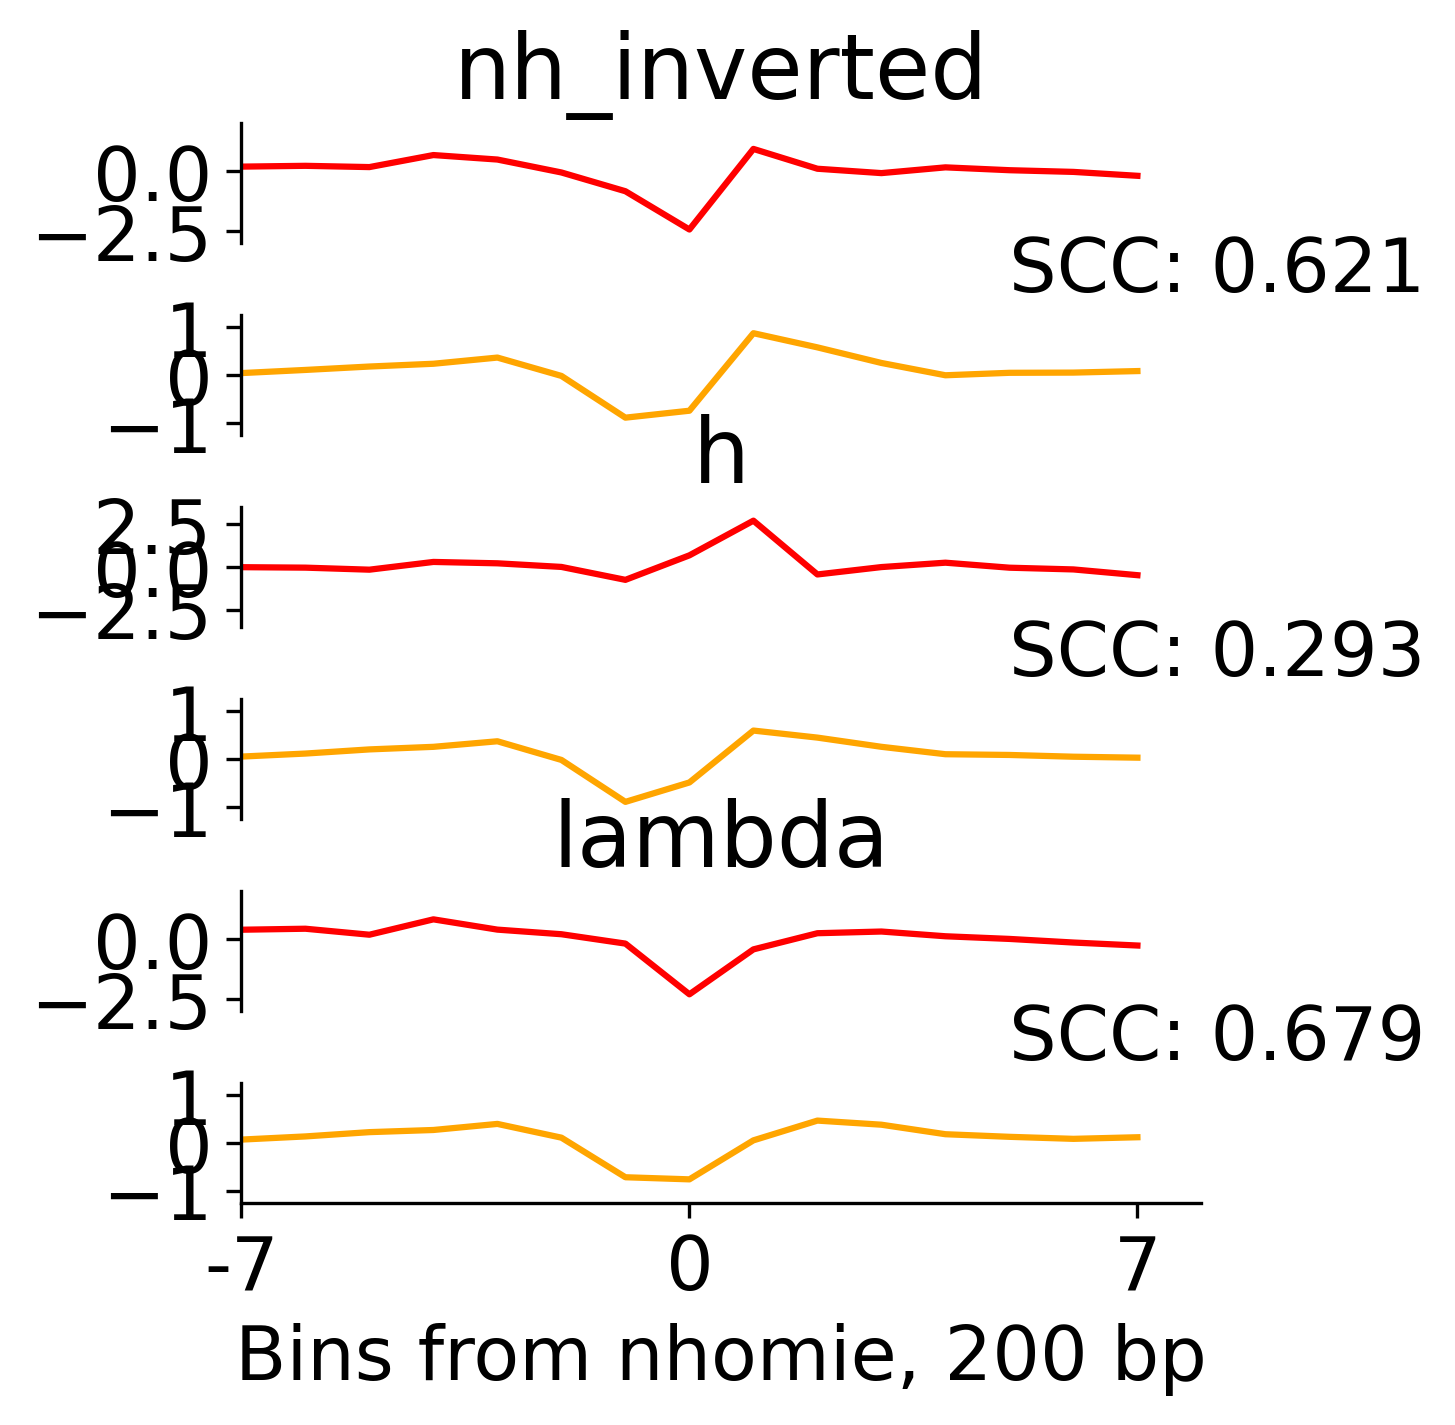

In [20]:
# plt.rcdefaults()
plt.rcParams['pdf.fonttype'] = '42'

# read in the reference track centered on reference boundary
ref_true = read_bedgraph_track(f'st14_nh_forward_mut_observed.bedGraph', coords=mut2coords['nh_forward'], window=1400//200)
ref_pred = read_bedgraph_track(f'st14_nh_forward_mut_predicted.bedGraph', coords=mut2coords['nh_forward'], window=1400//200)

fig, axs = init_subplots_exact(6,6,y_ratios=[0.1]*6, yspace=1.6, x_ratios=[0.8], dpi=300)

# read in the mutant tracks centered on reference boundary
for i, mut in enumerate(['nh_inverted', 'h', 'lambda']):
    mut_true = read_bedgraph_track(f'st14_{mut}_mut_observed.bedGraph', coords=mut2coords['nh_forward'], window=1400//200)
    mut_pred = read_bedgraph_track(f'st14_{mut}_mut_predicted.bedGraph', coords=mut2coords['nh_forward'], window=1400//200)
    

    true_delta = ref_true - mut_true
    pred_delta = ref_pred - mut_pred

    pcc = round(stats.pearsonr(true_delta, pred_delta)[0],3)
    scc = round(stats.spearmanr(true_delta, pred_delta)[0],3)


    axs[2*i].plot(true_delta, color='red', label='true')
    axs[2*i+1].plot(pred_delta, color='orange', label='pred')
    axs[2*i].set_title(f'{mut}')
    if mut == 'h':
        axs[2*i].set_ylim(-3.5, 3.5)
    else:
        axs[2*i].set_ylim(-3,2)
    axs[2*i+1].set_ylim(-1.25,1.25)
    axs[2*i+1].text(12, 1.75, f'SCC: {scc}')
    
for ax in axs:
    ax.yaxis.set_label_coords(-0.25, 0.25) 
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.set_xlim([0, 15])
    
for ax in axs[:-1]:
    ax.set_xticklabels([])
    ax.xaxis.set_ticks([])
    
axs[-1].set_xticks([0, 7, 14])
axs[-1].set_xticklabels([-7, 0, 7])
axs[-1].spines['bottom'].set_visible(True)
axs[-1].set_xlabel('Bins from nhomie, 200 bp')



plt.savefig(f"plots/boundary_replacement.pdf", format="pdf", bbox_inches='tight')
plt.show()
